In [11]:
import pandas as pd
import matplotlib.pyplot as plt

In [15]:
df = pd.read_csv('Employee.csv')

df.head()

,Education,JoiningYear,City,PaymentTier,Age,Gender,EverBenched,ExperienceInCurrentDomain,LeaveOrNot
0,Bachelors,2017,Bangalore,3,34,Male,No,0,0
1,Bachelors,2013,Pune,1,28,Female,No,3,1
2,Bachelors,2014,New Delhi,3,38,Female,No,2,0
3,Masters,2016,Bangalore,3,27,Male,No,5,1
4,Masters,2017,Pune,3,24,Male,Yes,2,1


In [16]:

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4653 entries, 0 to 4652
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   Education                  4653 non-null   str  
 1   JoiningYear                4653 non-null   int64
 2   City                       4653 non-null   str  
 3   PaymentTier                4653 non-null   int64
 4   Age                        4653 non-null   int64
 5   Gender                     4653 non-null   str  
 6   EverBenched                4653 non-null   str  
 7   ExperienceInCurrentDomain  4653 non-null   int64
 8   LeaveOrNot                 4653 non-null   int64
dtypes: int64(5), str(4)
memory usage: 431.5 KB


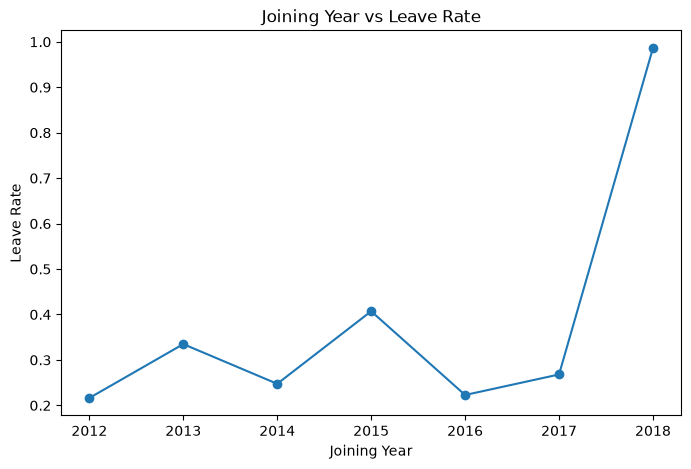

In [17]:
avg_leave = df.groupby('JoiningYear')['LeaveOrNot'].mean()

plt.figure(figsize=(8, 5))

plt.plot(avg_leave.index, avg_leave.values, marker='o')

plt.title('Joining Year vs Leave Rate')
plt.xlabel('Joining Year')
plt.ylabel('Leave Rate')

plt.show()

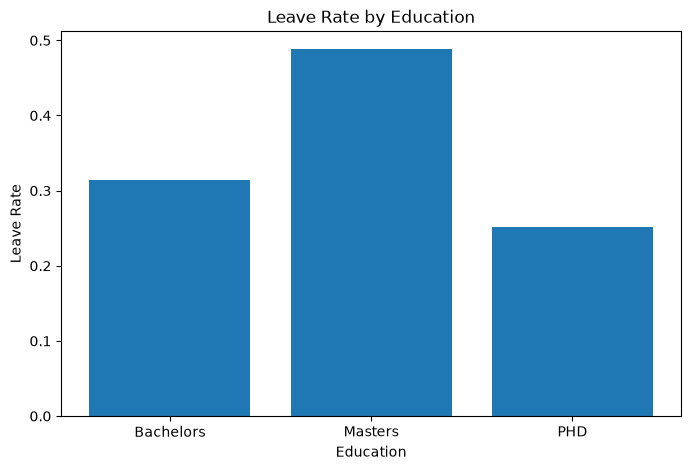

In [18]:
avg_leave = df.groupby('Education')['LeaveOrNot'].mean()

plt.figure(figsize=(8, 5))

plt.bar(avg_leave.index, avg_leave.values)

plt.title('Leave Rate by Education')
plt.xlabel('Education')
plt.ylabel('Leave Rate')

plt.show()

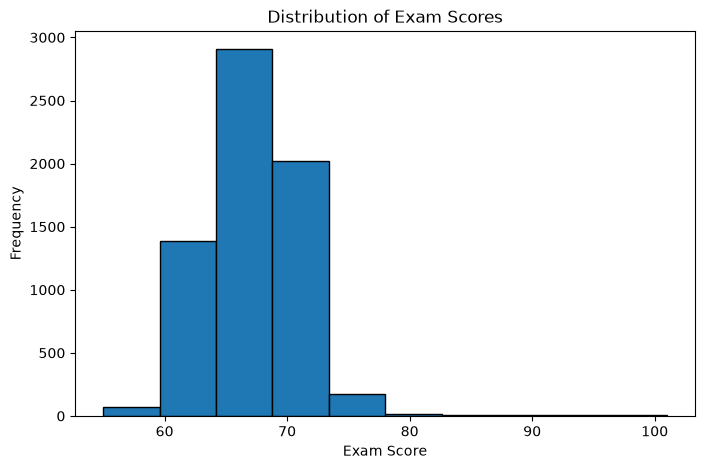

In [ ]:
plt.figure(figsize=(8, 5))

plt.hist(df['Age'], bins=10, edgecolor='black')

plt.title('Employee Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')

plt.show()

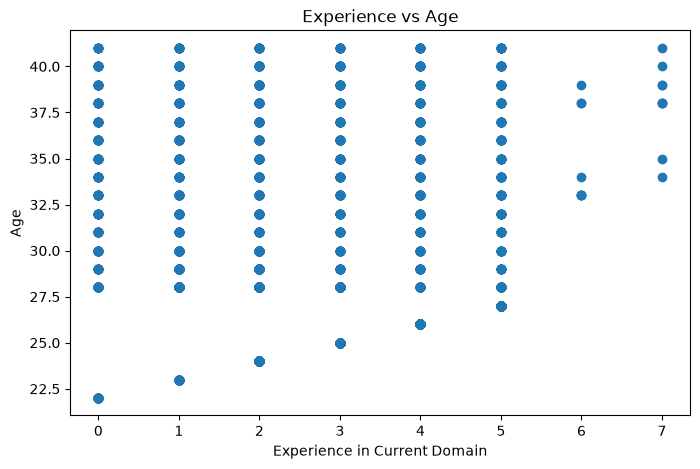

In [19]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df['ExperienceInCurrentDomain'],
    df['Age']
)

plt.title('Experience vs Age')
plt.xlabel('Experience in Current Domain')
plt.ylabel('Age')

plt.show()

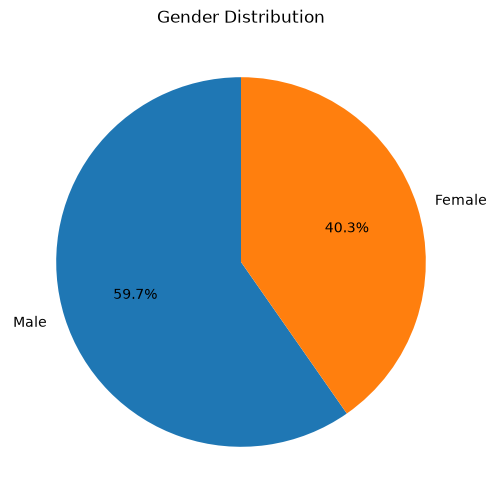

In [23]:
gender_counts = df['Gender'].value_counts()

plt.figure(figsize=(6, 6))

plt.pie(
    gender_counts.values,
    labels=gender_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Gender Distribution')

plt.show()

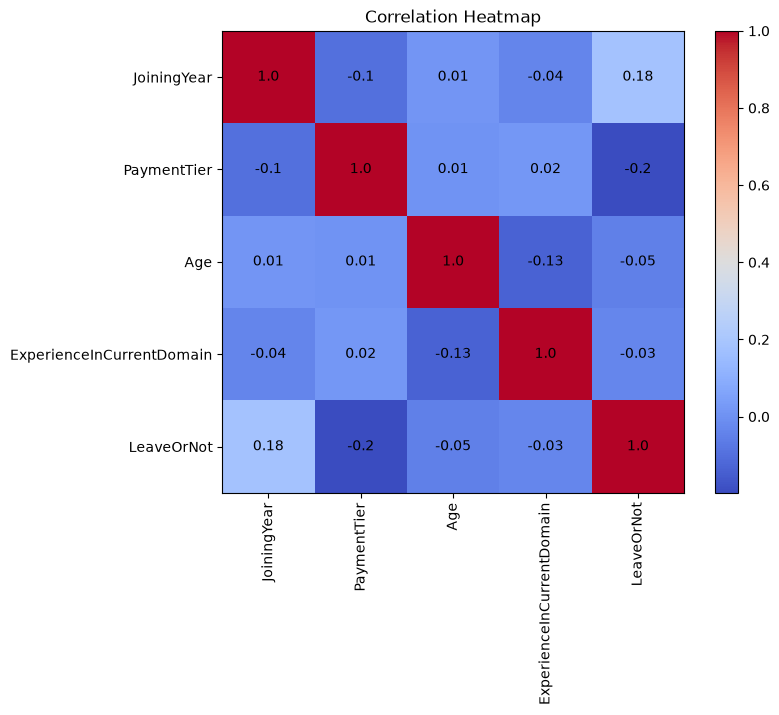

In [24]:
corr = df.select_dtypes(include='number').corr()

plt.figure(figsize=(8, 6))

plt.imshow(corr, cmap='coolwarm')

plt.xticks(
    range(len(corr.columns)),
    corr.columns,
    rotation=90
)

plt.yticks(
    range(len(corr.columns)),
    corr.columns
)

for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        plt.text(
            j,
            i,
            round(corr.iloc[i, j], 2),
            ha='center',
            va='center'
        )

plt.colorbar()

plt.title('Correlation Heatmap')

plt.show()